# T04 · EDA: idade, sexo, altura, peso e IMC

**Issue:** #4 · **Fase 1 · EDA** · **Dataset:** `data/raw/cardio_train.csv`

**Objetivo:** analisar as variáveis demográficas e corporais e encontrar os valores impossíveis de altura e peso. As faixas propostas no fim alimentam a **T08** (limpeza) e o IMC alimenta a **T10** (features).

> A análise é feita sobre os **dados brutos**, sem limpeza, justamente para encontrar os problemas.
> Todos os números dos textos são **calculados a partir do dataset**. As faixas plausíveis e as faixas de IMC vêm de `src/cardio/config.py`.

In [1]:
import sys
from pathlib import Path

# Permite rodar o notebook fora do Docker (no Docker o PYTHONPATH já aponta para src/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from cardio.config import IMC_BINS, IMC_LABELS, DATA_PATH, FIGURES_DIR, PLAUSIBLE_RANGES
from cardio.data.loader import load_raw

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
CLASSES = {0: "Sem doença", 1: "Com doença"}


def salvar(fig, nome: str) -> None:
    """Salva a figura em results/figures/ com o prefixo da tarefa."""
    fig.savefig(FIGURES_DIR / f"t04_{nome}.png", dpi=120, bbox_inches="tight")


def pct(valor: float, casas: int = 0) -> str:
    """Formata uma proporção (0–1) como porcentagem no padrão brasileiro: 0.497 -> '49,7%'."""
    return f"{valor * 100:.{casas}f}%".replace(".", ",")


def num(valor: float, casas: int = 2) -> str:
    """Formata um número com vírgula decimal: 0.238 -> '0,24'."""
    return f"{valor:.{casas}f}".replace(".", ",")


def inteiro(valor: int) -> str:
    """Formata um inteiro com ponto de milhar: 68588 -> '68.588'."""
    return f"{valor:,}".replace(",", ".")


def texto(conteudo: str) -> None:
    """Mostra um texto de interpretação formatado em Markdown."""
    display(Markdown(conteudo))

In [2]:
df = load_raw(DATA_PATH)

# Variáveis derivadas usadas nesta análise
df["age_years"] = df["age"] / 365.25
df["sexo"] = df["gender"].map({1: "Feminino", 2: "Masculino"})
df["imc"] = df["weight"] / (df["height"] / 100) ** 2
df["classe"] = df["cardio"].map(CLASSES)

print(f"{inteiro(len(df))} pacientes")
df[["age_years", "height", "weight", "imc"]].describe().round(1)

70.000 pacientes


,age_years,height,weight,bmi
count,70000.0,70000.0,70000.0,70000.0
mean,53.3,164.4,74.2,27.6
std,6.8,8.2,14.4,6.1
min,29.6,55.0,10.0,3.5
25%,48.4,159.0,65.0,23.9
50%,53.9,165.0,72.0,26.4
75%,58.4,170.0,82.0,30.2
max,64.9,250.0,200.0,298.7


## 1. Idade × doença cardiovascular

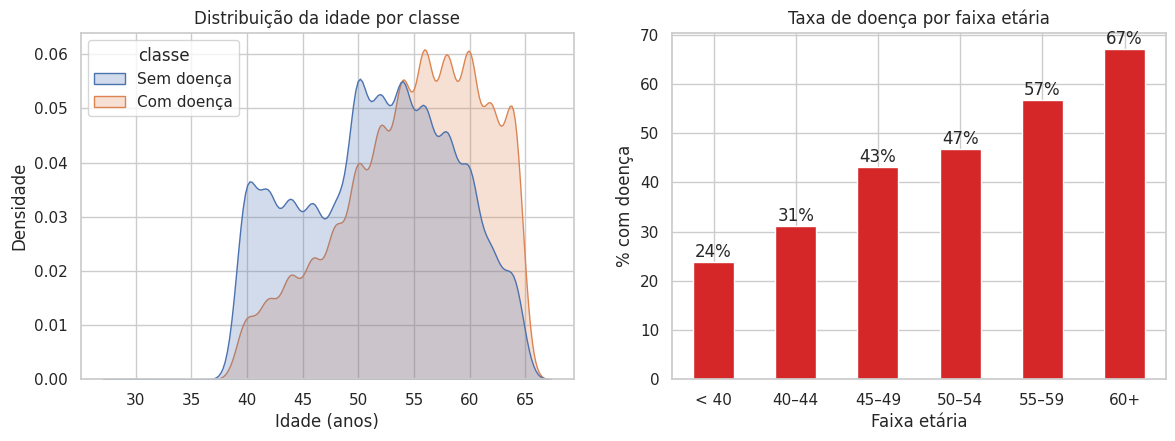

Correlação idade × cardio: 0.238


,count,mean,std,min,25%,50%,75%,max
classe,,,,,,,,
Com doença,34979.0,54.9,6.3,39.1,50.3,55.8,60.0,64.9
Sem doença,35021.0,51.7,6.8,29.6,46.1,52.0,57.2,64.8


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.kdeplot(data=df, x="age_years", hue="classe", fill=True, common_norm=False, ax=axes[0])
axes[0].set(title="Distribuição da idade por classe", xlabel="Idade (anos)", ylabel="Densidade")

df["faixa_etaria"] = pd.cut(df["age_years"], [0, 40, 45, 50, 55, 60, 70], right=False,
                            labels=["< 40", "40–44", "45–49", "50–54", "55–59", "60+"])
taxa_idade = df.groupby("faixa_etaria", observed=True)["cardio"].mean()
(taxa_idade * 100).plot(kind="bar", ax=axes[1], color="tab:red")
axes[1].set(title="Taxa de doença por faixa etária", xlabel="Faixa etária", ylabel="% com doença")
axes[1].tick_params(axis="x", rotation=0)
for i, v in enumerate(taxa_idade):
    axes[1].text(i, v * 100 + 1, pct(v), ha="center")

salvar(fig, "idade_por_classe")
plt.show()

corr_idade = df["age_years"].corr(df["cardio"])
mediana_idade = df.groupby("cardio")["age_years"].median()
print("Correlação idade × cardio:", round(corr_idade, 3))
df.groupby("classe")["age_years"].describe().round(1)

In [4]:
cresce_com_idade = taxa_idade.is_monotonic_increasing
texto(f"""**Interpretação:** {"sim, a doença aumenta com a idade" if cresce_com_idade else "a taxa de doença não cresce de forma contínua com a idade"}.
A correlação com o alvo é **{num(corr_idade)}**. A idade mediana é **{num(mediana_idade[0], 0)} anos** no grupo sem doença
e **{num(mediana_idade[1], 0)} anos** no grupo com doença. A taxa de doença vai de **{pct(taxa_idade.iloc[0])}**
na faixa {taxa_idade.index[0]} para **{pct(taxa_idade.iloc[-1])}** na faixa {taxa_idade.index[-1]}.

A idade vai de {num(df["age_years"].min(), 1)} a {num(df["age_years"].max(), 1)} anos. Ela vem em **dias** no CSV,
então precisa ser convertida para anos.""")

**Interpretação:** sim, a doença aumenta com a idade.
A correlação com o alvo é **0,24**. A idade mediana é **52 anos** no grupo sem doença
e **56 anos** no grupo com doença. A taxa de doença vai de **24%**
na faixa < 40 para **67%** na faixa 60+.

A idade vai de 29,6 a 64,9 anos. Ela vem em **dias** no CSV,
então precisa ser convertida para anos.

## 2. Sexo

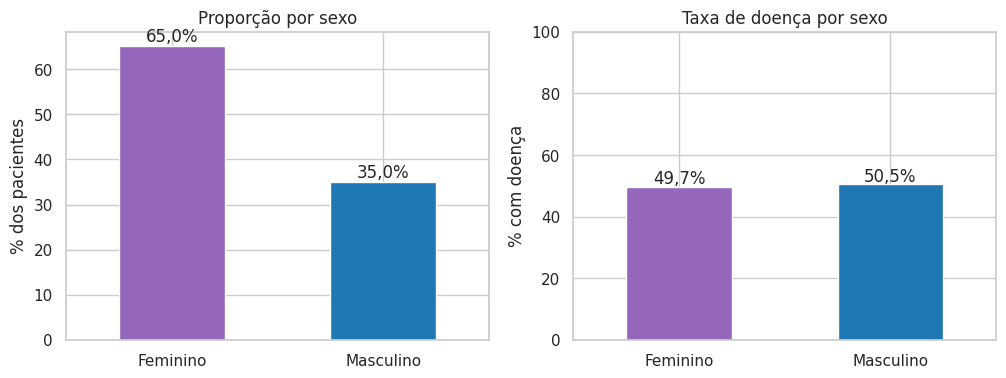

,height,weight
sexo,,
Feminino,161.4,72.6
Masculino,169.9,77.3


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

prop_sexo = df["sexo"].value_counts(normalize=True)
(prop_sexo * 100).plot(kind="bar", ax=axes[0], color=["tab:purple", "tab:blue"])
axes[0].set(title="Proporção por sexo", xlabel="", ylabel="% dos pacientes")
axes[0].tick_params(axis="x", rotation=0)

taxa_sexo = df.groupby("sexo")["cardio"].mean()
(taxa_sexo * 100).plot(kind="bar", ax=axes[1], color=["tab:purple", "tab:blue"])
axes[1].set(title="Taxa de doença por sexo", xlabel="", ylabel="% com doença", ylim=(0, 100))
axes[1].tick_params(axis="x", rotation=0)
for ax, serie in ((axes[0], prop_sexo), (axes[1], taxa_sexo)):
    for i, v in enumerate(serie):
        ax.text(i, v * 100 + 1, pct(v, 1), ha="center")

salvar(fig, "sexo")
plt.show()

medidas_sexo = df.groupby("sexo")[["height", "weight"]].mean()
medidas_sexo.round(1)

In [6]:
diferenca_sexo = abs(taxa_sexo["Feminino"] - taxa_sexo["Masculino"])
texto(f"""**Interpretação:** o dataset tem **{pct(prop_sexo["Feminino"])} de mulheres** e {pct(prop_sexo["Masculino"])} de homens.
A codificação é `gender = 1` para mulheres e `2` para homens: a altura média do grupo 1 é
{num(medidas_sexo.loc["Feminino", "height"], 0)} cm e a do grupo 2 é {num(medidas_sexo.loc["Masculino", "height"], 0)} cm.

A taxa de doença é **{pct(taxa_sexo["Feminino"], 1)}** nas mulheres e **{pct(taxa_sexo["Masculino"], 1)}** nos homens,
{"praticamente igual: sozinho, o sexo diz pouco sobre a doença" if diferenca_sexo < 0.02 else "uma diferença relevante entre os sexos"}.
O desequilíbrio da amostra precisa entrar na discussão de limitações (T34) e na análise por subgrupo (T26).""")

**Interpretação:** o dataset tem **65% de mulheres** e 35% de homens.
A codificação é `gender = 1` para mulheres e `2` para homens: a altura média do grupo 1 é
161 cm e a do grupo 2 é 170 cm.

A taxa de doença é **49,7%** nas mulheres e **50,5%** nos homens,
praticamente igual: sozinho, o sexo diz pouco sobre a doença.
O desequilíbrio da amostra precisa entrar na discussão de limitações (T34) e na análise por subgrupo (T26).

## 3. Altura e peso por classe

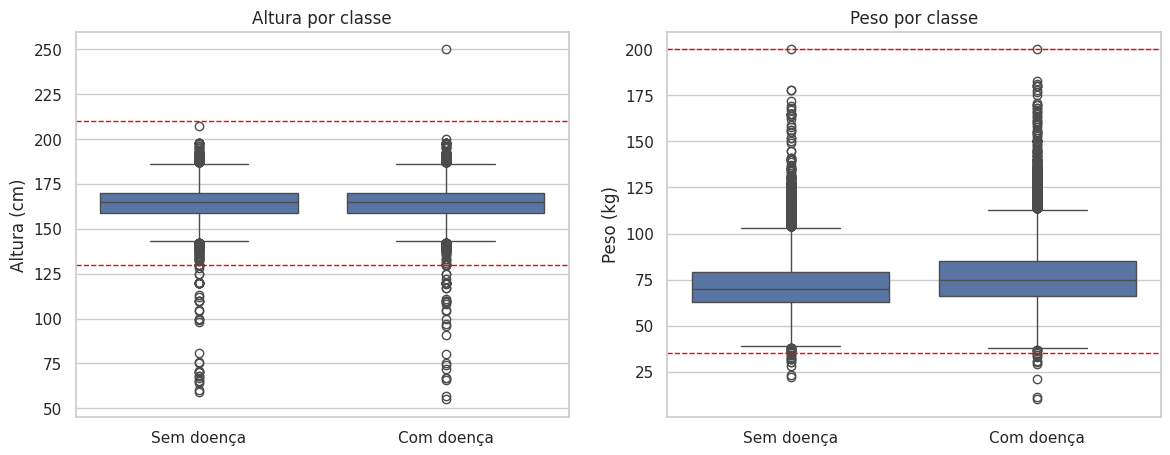

Correlação com cardio -> altura: -0.011 | peso: 0.182


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, titulo, unidade in zip(axes, ["height", "weight"], ["Altura", "Peso"], ["cm", "kg"]):
    sns.boxplot(data=df, x="classe", y=col, ax=ax)
    ax.set(title=f"{titulo} por classe", xlabel="", ylabel=f"{titulo} ({unidade})")
    lo, hi = PLAUSIBLE_RANGES[col]
    ax.axhline(lo, color="red", ls="--", lw=1)
    ax.axhline(hi, color="red", ls="--", lw=1)
salvar(fig, "altura_peso_por_classe")
plt.show()

corr_altura = df["height"].corr(df["cardio"])
corr_peso = df["weight"].corr(df["cardio"])
mediana_altura = df.groupby("cardio")["height"].median()
mediana_peso = df.groupby("cardio")["weight"].median()
print("Correlação com cardio -> altura:", round(corr_altura, 3), "| peso:", round(corr_peso, 3))

In [8]:
# Valores implausíveis, segundo as faixas de config.PLAUSIBLE_RANGES
(alt_min, alt_max), (peso_min, peso_max) = PLAUSIBLE_RANGES["height"], PLAUSIBLE_RANGES["weight"]
implausiveis = pd.Series({
    f"altura < {alt_min} cm": (df["height"] < alt_min).sum(),
    f"altura > {alt_max} cm": (df["height"] > alt_max).sum(),
    f"peso < {peso_min} kg": (df["weight"] < peso_min).sum(),
    f"peso > {peso_max} kg": (df["weight"] > peso_max).sum(),
}, name="casos")
display(implausiveis.to_frame())

# Exemplos: os registros mais baixos do dataset
df.loc[df["height"] < alt_min, ["age_years", "sexo", "height", "weight", "imc"]].sort_values("height").head(8).round(1)

,casos
altura < 130 cm,92
altura > 210 cm,1
peso < 35 kg,20
peso > 200 kg,0


,age_years,sexo,height,weight,bmi
22723,64.0,Feminino,55,81.0,267.8
66643,51.6,Feminino,57,61.0,187.8
64115,50.4,Feminino,59,57.6,165.5
29157,52.3,Feminino,60,69.0,191.7
27603,57.4,Feminino,64,61.0,148.9
33607,54.0,Masculino,65,72.0,170.4
44490,52.3,Feminino,65,60.0,142.0
64454,58.4,Feminino,66,63.0,144.6


In [9]:
texto(f"""**Interpretação:** a correlação da altura com a doença é **{num(corr_altura)}**
(mediana de {num(mediana_altura[0], 0)} cm sem doença e {num(mediana_altura[1], 0)} cm com doença), ou seja,
{"praticamente nenhuma relação" if abs(corr_altura) < 0.05 else "alguma relação"}. O peso tem correlação de **{num(corr_peso)}**,
com mediana de {num(mediana_peso[0], 0)} kg no grupo sem doença e **{num(mediana_peso[1], 0)} kg** no grupo com doença.

As linhas vermelhas marcam as faixas propostas. Fora delas há registros claramente errados, provavelmente de digitação:
a menor altura é **{num(df["height"].min(), 0)} cm** e o menor peso é **{num(df["weight"].min(), 0)} kg**.
São **{implausiveis.iloc[0]}** casos com altura abaixo de {alt_min} cm, **{implausiveis.iloc[1]}** acima de {alt_max} cm,
**{implausiveis.iloc[2]}** com peso abaixo de {peso_min} kg e **{implausiveis.iloc[3]}** acima de {peso_max} kg.""")

**Interpretação:** a correlação da altura com a doença é **-0,01**
(mediana de 165 cm sem doença e 165 cm com doença), ou seja,
praticamente nenhuma relação. O peso tem correlação de **0,18**,
com mediana de 70 kg no grupo sem doença e **75 kg** no grupo com doença.

As linhas vermelhas marcam as faixas propostas. Fora delas há registros claramente errados, provavelmente de digitação:
a menor altura é **55 cm** e o menor peso é **10 kg**.
São **92** casos com altura abaixo de 130 cm, **1** acima de 210 cm,
**20** com peso abaixo de 35 kg e **0** acima de 200 kg.

## 4. IMC

IMC < 15: 27 | IMC > 60: 66


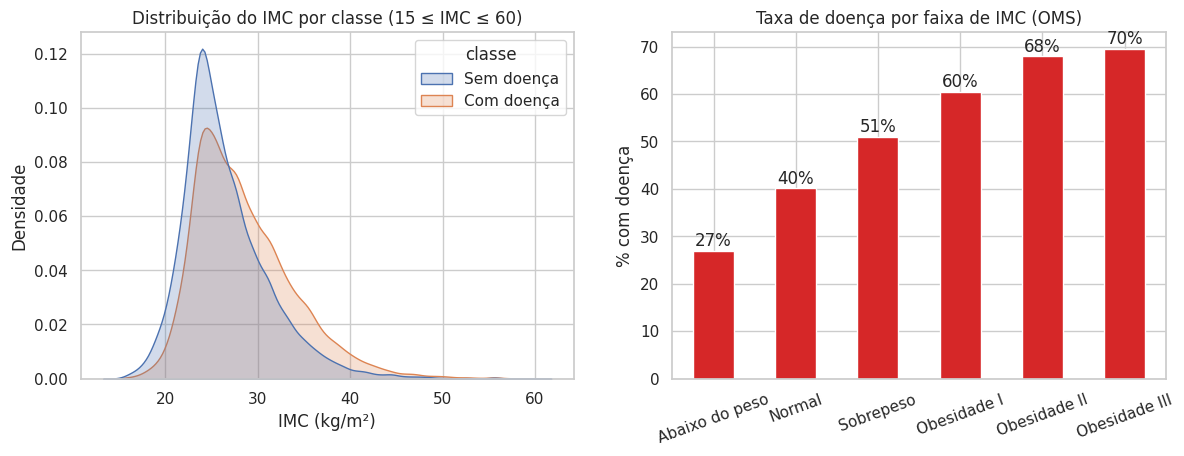

Correlação IMC × cardio (IMC válido): 0.193


,pacientes,taxa_doenca
imc_faixa,,
Abaixo do peso,623,27.0
Normal,25790,40.1
Sobrepeso,25086,51.0
Obesidade I,12212,60.4
Obesidade II,4376,68.0
Obesidade III,1820,69.6


In [10]:
df["faixa_imc"] = pd.cut(df["imc"], IMC_BINS, right=False, labels=IMC_LABELS)
imc_min, imc_max = PLAUSIBLE_RANGES["imc"]
imc_valido = df["imc"].between(imc_min, imc_max)
imc_baixo, imc_alto = (df["imc"] < imc_min).sum(), (df["imc"] > imc_max).sum()
print(f"IMC < {imc_min}: {imc_baixo} | IMC > {imc_max}: {imc_alto}")

tabela_imc = (df[imc_valido].groupby("faixa_imc", observed=True)["cardio"]
              .agg(pacientes="size", taxa_doenca="mean"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.kdeplot(data=df[imc_valido], x="imc", hue="classe", fill=True, common_norm=False, ax=axes[0])
axes[0].set(title=f"Distribuição do IMC por classe ({imc_min} ≤ IMC ≤ {imc_max})", xlabel="IMC (kg/m²)", ylabel="Densidade")
(tabela_imc["taxa_doenca"] * 100).plot(kind="bar", ax=axes[1], color="tab:red")
axes[1].set(title="Taxa de doença por faixa de IMC (OMS)", xlabel="", ylabel="% com doença")
axes[1].tick_params(axis="x", rotation=20)
for i, v in enumerate(tabela_imc["taxa_doenca"]):
    axes[1].text(i, v * 100 + 1, pct(v), ha="center")
salvar(fig, "imc")
plt.show()

corr_imc = df.loc[imc_valido, "imc"].corr(df.loc[imc_valido, "cardio"])
print("Correlação IMC × cardio (IMC válido):", round(corr_imc, 3))
tabela_imc.assign(taxa_doenca=(tabela_imc["taxa_doenca"] * 100).round(1))

In [11]:
taxas = tabela_imc["taxa_doenca"]
texto(f"""**Interpretação:** o IMC mostra uma relação {"clara e crescente" if taxas.is_monotonic_increasing else "não contínua"} com a doença.
A taxa vai de **{pct(taxas.iloc[0])}** ({taxas.index[0].lower()}) para **{pct(taxas["Normal"])}** no peso normal,
**{pct(taxas["Sobrepeso"])}** no sobrepeso e chega a **{pct(taxas.iloc[-1])}** na {taxas.index[-1]}.

A correlação com o alvo (**{num(corr_imc)}**) é {"maior" if corr_imc > corr_peso else "menor"} que a do peso sozinho
({num(corr_peso)}){", o que reforça o IMC como feature para a **T10**" if corr_imc > corr_peso else ""}.
O IMC também pega erros que passam nos limites separados de altura e peso: **{imc_baixo}** casos com IMC abaixo de {imc_min}
e **{imc_alto}** acima de {imc_max}, fisiologicamente improváveis para adultos.""")

**Interpretação:** o IMC mostra uma relação clara e crescente com a doença.
A taxa vai de **27%** (abaixo do peso) para **40%** no peso normal,
**51%** no sobrepeso e chega a **70%** na Obesidade III.

A correlação com o alvo (**0,19**) é maior que a do peso sozinho
(0,18), o que reforça o IMC como feature para a **T10**.
O IMC também pega erros que passam nos limites separados de altura e peso: **27** casos com IMC abaixo de 15
e **66** acima de 60, fisiologicamente improváveis para adultos.

## 5. Faixas plausíveis propostas (para a T08)

As faixas estão em `config.PLAUSIBLE_RANGES`, para que a T08 use exatamente os mesmos valores.

In [12]:
VARIAVEIS = {
    "height": ("Altura", "cm", "Adultos fora dessa faixa são raríssimos; os casos fora são erros de registro."),
    "weight": ("Peso", "kg", "Abaixo do mínimo é incompatível com adultos nessas alturas."),
    "imc": ("IMC", "kg/m²", "Pega combinações altura/peso inválidas que passam nos limites separados."),
}
proposta = pd.DataFrame([
    {"Variável": nome, "Faixa plausível": f"{lo}–{hi} {unidade}",
     "Casos fora": int((~df[col].between(lo, hi)).sum()), "Justificativa": justificativa}
    for col, (lo, hi) in PLAUSIBLE_RANGES.items()
    for nome, unidade, justificativa in [VARIAVEIS[col]]
])

dentro = pd.concat([df[col].between(lo, hi) for col, (lo, hi) in PLAUSIBLE_RANGES.items()], axis=1).all(axis=1)
removidas = int((~dentro).sum())
print(f"Total removido aplicando as três regras: {inteiro(removidas)} linhas ({pct(removidas / len(df), 2)})")
pd.set_option("display.max_colwidth", None)
proposta

Total removido aplicando as três regras: 147 linhas (0,21%)


,Variável,Faixa plausível,Casos fora,Justificativa
0,Altura,130–210 cm,93,Adultos fora dessa faixa são raríssimos; os casos fora são erros de registro.
1,Peso,35–200 kg,20,Abaixo do mínimo é incompatível com adultos nessas alturas.
2,IMC,15–60 kg/m²,93,Pega combinações altura/peso inválidas que passam nos limites separados.


In [13]:
faixas = "; ".join(f"{VARIAVEIS[c][0] if c == 'imc' else VARIAVEIS[c][0].lower()} entre **{lo} e {hi} {VARIAVEIS[c][1]}**" for c, (lo, hi) in PLAUSIBLE_RANGES.items())
texto(f"""### Conclusões

- **Idade** é a variável demográfica mais associada à doença (correlação {num(corr_idade)}): a taxa vai de
  {pct(taxa_idade.iloc[0])} ({taxa_idade.index[0]} anos) a {pct(taxa_idade.iloc[-1])} ({taxa_idade.index[-1]}).
- **Sexo**: taxa de doença de {pct(taxa_sexo["Feminino"], 1)} (mulheres) × {pct(taxa_sexo["Masculino"], 1)} (homens),
  com amostra **{pct(prop_sexo["Feminino"])} feminina**, uma limitação a registrar.
- **Altura** (correlação {num(corr_altura)}) praticamente não se relaciona com a doença; **peso** tem relação moderada ({num(corr_peso)}).
- **IMC** (correlação {num(corr_imc)}) tem relação crescente com a doença e deve virar feature (**T10**).
- **Proposta para a T08:** {faixas}. Juntas, essas regras removem **{inteiro(removidas)} linhas ({pct(removidas / len(df), 2)})**.

As figuras foram salvas em `results/figures/` com o prefixo `t04_`.""")

### Conclusões

- **Idade** é a variável demográfica mais associada à doença (correlação 0,24): a taxa vai de
  24% (< 40 anos) a 67% (60+).
- **Sexo**: taxa de doença de 49,7% (mulheres) × 50,5% (homens),
  com amostra **65% feminina**, uma limitação a registrar.
- **Altura** (correlação -0,01) praticamente não se relaciona com a doença; **peso** tem relação moderada (0,18).
- **IMC** (correlação 0,19) tem relação crescente com a doença e deve virar feature (**T10**).
- **Proposta para a T08:** altura entre **130 e 210 cm**; peso entre **35 e 200 kg**; IMC entre **15 e 60 kg/m²**. Juntas, essas regras removem **147 linhas (0,21%)**.

As figuras foram salvas em `results/figures/` com o prefixo `t04_`.